# 06 · Fan-base "spatial" analysis

The YouTube API does not return commenter location, and only 5.6% of commenter channels list a country (almost all US). Instead, each comment is tagged with the teams it mentions: names, short forms and chants such as "Bama", "Roll Tide", "Go Dawgs", "Hook 'em". Each team is mapped to its home state and its 2026 conference (SEC, Big Ten, ACC, Big 12, Notre Dame, Group of 6).

**Location here is inferred from the teams people talk about, not measured.** Mentioning a team is not the same as being its fan: a lot of comments are rivals mocking a team. Read the results as "sentiment in comments *about* each fan base's team".

In [1]:
import sys
import re
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import config

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 110)
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

CREATOR_NAMES = {"pate": "Josh Pate", "crain_cone": "Crain & Cone"}
CREATOR_COLORS = {"Josh Pate": "#1f5fa8", "Crain & Cone": "#d9822b"}
PERIOD_ORDER = ["before", "announcement", "after"]

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
df = pd.read_csv(config.DATA_DIR / "comments_scored.csv", keep_default_na=False,
                 parse_dates=["published_utc", "updated_utc", "video_published_utc"])
df["country"] = df["country"].replace("", np.nan)
df["creator_name"] = df["creator"].map(CREATOR_NAMES)
df.shape

(9456, 37)

In [3]:
# Main score: VADER with the sports word list (chosen with the hand labels in notebook 04).
SCORE, LABEL, SCORE_NAME = "vader_sports_compound", "vader_sports_label", "VADER + sports"

from scipy import stats
import statsmodels.formula.api as smf

def compare(a, b):
    """Welch t-test, Mann-Whitney U and Cohen's d for two score samples."""
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    t, p_t = stats.ttest_ind(b, a, equal_var=False)
    _, p_u = stats.mannwhitneyu(b, a, alternative="two-sided")
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return pd.Series({"n_a": len(a), "n_b": len(b), "mean_a": a.mean(), "mean_b": b.mean(),
                      "diff": b.mean() - a.mean(), "cohens_d": (b.mean() - a.mean()) / pooled,
                      "p_welch": p_t, "p_mannwhitney": p_u})

def neg_share(s):
    return (s == "negative").mean()

## Team / chant dictionary → state and conference

Each entry: team, state, conference, a case-insensitive pattern and an optional case-sensitive pattern for short capital forms (`UT`, `ND`, `IU`, `OU`), which would otherwise match ordinary words.

Aliases that matched ordinary text in testing were left out on purpose: "we are" (Penn State), "um" (Michigan), and shared nicknames such as Cougars, Tigers, Wildcats, Bulldogs and Panthers. Lookaheads keep "Texas" from matching "Texas Tech" and "Michigan" from matching "Michigan State". "OSU" is counted as Ohio State, which is how these audiences use it.

In [4]:
# (team, state, conference, case-insensitive pattern, case-sensitive pattern or None)
TEAMS = [
    # SEC
    ("Alabama", "AL", "SEC", r"alabama|bama|roll tide|crimson tide", None),
    ("Auburn", "AL", "SEC", r"auburn|war eagle", None),
    ("Georgia", "GA", "SEC", r"georgia(?! tech| state| southern)|go dawgs|uga", None),
    ("Florida", "FL", "SEC", r"florida(?! state| atlantic| international)|gators", r"UF"),
    ("LSU", "LA", "SEC", r"lsu|geaux tigers", None),
    ("Ole Miss", "MS", "SEC", r"ole miss|lane train|hotty toddy", None),
    ("Mississippi State", "MS", "SEC", r"mississippi state|miss(?:issippi)? st(?:ate)?\b|hail state", None),
    ("Tennessee", "TN", "SEC", r"tennessee|vols|volunteers|rocky top", None),
    ("Texas", "TX", "SEC", r"texas(?! a&m| a and m| tech| state)|longhorns|hook ?'?em|horns", r"UT"),
    ("Texas A&M", "TX", "SEC", r"texas a&m|texas a and m|a&m|aggies|gig ?'?em", r"TAMU"),
    ("Oklahoma", "OK", "SEC", r"oklahoma(?! state)|sooners|boomer sooner", r"OU"),
    ("Missouri", "MO", "SEC", r"missouri|mizzou", None),
    ("South Carolina", "SC", "SEC", r"south carolina|gamecocks", None),
    ("Kentucky", "KY", "SEC", r"kentucky", r"UK"),
    ("Arkansas", "AR", "SEC", r"arkansas|razorbacks|woo pig", None),
    ("Vanderbilt", "TN", "SEC", r"vanderbilt|vandy|commodores", None),
    # Big Ten
    ("Ohio State", "OH", "Big Ten", r"ohio state|buckeyes|o-h-i-o|osu", None),
    ("Michigan", "MI", "Big Ten", r"michigan(?! state)|wolverines|go blue", None),
    ("Michigan State", "MI", "Big Ten", r"michigan state|msu|spartans", None),
    ("Penn State", "PA", "Big Ten", r"penn state|psu|nittany", None),
    ("Oregon", "OR", "Big Ten", r"oregon(?! state)|ducks", None),
    ("Indiana", "IN", "Big Ten", r"indiana|hoosiers|cignetti", r"IU"),
    ("USC", "CA", "Big Ten", r"usc|trojans|fight on", None),
    ("UCLA", "CA", "Big Ten", r"ucla|bruins", None),
    ("Washington", "WA", "Big Ten", r"washington(?! state)|huskies|uw", None),
    ("Iowa", "IA", "Big Ten", r"iowa(?! state)|hawkeyes", None),
    ("Nebraska", "NE", "Big Ten", r"nebraska|huskers|cornhuskers", None),
    ("Wisconsin", "WI", "Big Ten", r"wisconsin|badgers", None),
    ("Minnesota", "MN", "Big Ten", r"minnesota|gophers", None),
    ("Illinois", "IL", "Big Ten", r"illinois|illini", None),
    ("Northwestern", "IL", "Big Ten", r"northwestern", None),
    ("Purdue", "IN", "Big Ten", r"purdue|boilermakers", None),
    ("Maryland", "MD", "Big Ten", r"maryland|terps|terrapins", None),
    ("Rutgers", "NJ", "Big Ten", r"rutgers", None),
    # ACC
    ("Miami", "FL", "ACC", r"miami(?! of ohio| \(oh)|hurricanes|the u\b|canes", None),
    ("Clemson", "SC", "ACC", r"clemson|dabo", None),
    ("Florida State", "FL", "ACC", r"florida state|seminoles|noles|fsu", None),
    ("Louisville", "KY", "ACC", r"louisville", None),
    ("SMU", "TX", "ACC", r"smu", None),
    ("Georgia Tech", "GA", "ACC", r"georgia tech|yellow jackets", None),
    ("North Carolina", "NC", "ACC", r"north carolina|tar heels|unc|belichick", None),
    ("NC State", "NC", "ACC", r"nc state|n\.c\. state|wolfpack", None),
    ("Duke", "NC", "ACC", r"duke|blue devils", None),
    ("Virginia Tech", "VA", "ACC", r"virginia tech|hokies", None),
    ("Virginia", "VA", "ACC", r"(?<!west )virginia(?! tech)|cavaliers|wahoos", r"UVA"),
    ("Pitt", "PA", "ACC", r"pitt|pittsburgh", None),
    ("Syracuse", "NY", "ACC", r"syracuse", None),
    ("Boston College", "MA", "ACC", r"boston college", r"BC"),
    ("Wake Forest", "NC", "ACC", r"wake forest", None),
    ("Cal", "CA", "ACC", r"cal bears|california golden|cal\b(?!\.)", None),
    ("Stanford", "CA", "ACC", r"stanford", None),
    # Big 12
    ("Texas Tech", "TX", "Big 12", r"texas tech|red raiders|guns up", r"TTU"),
    ("BYU", "UT", "Big 12", r"byu", None),
    ("Utah", "UT", "Big 12", r"utah(?! state)|utes", None),
    ("Arizona State", "AZ", "Big 12", r"arizona state|sun devils|asu", None),
    ("Arizona", "AZ", "Big 12", r"arizona(?! state)", None),
    ("Colorado", "CO", "Big 12", r"colorado(?! state)|buffs|buffaloes|deion|coach prime", None),
    ("Iowa State", "IA", "Big 12", r"iowa state|cyclones", None),
    ("Kansas State", "KS", "Big 12", r"kansas state|k-state|k state", None),
    ("Kansas", "KS", "Big 12", r"kansas(?! state| city)|jayhawks", r"KU"),
    ("Oklahoma State", "OK", "Big 12", r"oklahoma state|okie state", None),
    ("Baylor", "TX", "Big 12", r"baylor", None),
    ("TCU", "TX", "Big 12", r"tcu|horned frogs", None),
    ("Houston", "TX", "Big 12", r"houston(?! texans)", r"UH"),
    ("Cincinnati", "OH", "Big 12", r"cincinnati|bearcats", None),
    ("UCF", "FL", "Big 12", r"ucf|central florida", None),
    ("West Virginia", "WV", "Big 12", r"west virginia|wvu|mountaineers", None),
    # Notre Dame
    ("Notre Dame", "IN", "Notre Dame", r"notre dame|fighting irish|irish|domers", r"ND"),
    # Group of 6 (incl. the rebuilt Pac-12)
    ("Boise State", "ID", "Group of 6", r"boise state|boise", None),
    ("Tulane", "LA", "Group of 6", r"tulane|green wave", None),
    ("Army", "NY", "Group of 6", r"army|black knights", None),
    ("Navy", "MD", "Group of 6", r"navy|midshipmen", None),
    ("James Madison", "VA", "Group of 6", r"james madison|jmu", None),
    ("Memphis", "TN", "Group of 6", r"memphis", None),
    ("UNLV", "NV", "Group of 6", r"unlv", None),
    ("South Florida", "FL", "Group of 6", r"south florida|usf", None),
    ("North Texas", "TX", "Group of 6", r"north texas|mean green", None),
    ("Liberty", "VA", "Group of 6", r"liberty flames", None),
    ("San Diego State", "CA", "Group of 6", r"san diego state|sdsu|aztecs", None),
    ("Toledo", "OH", "Group of 6", r"toledo", None),
    ("Old Dominion", "VA", "Group of 6", r"old dominion|odu", None),
    ("East Carolina", "NC", "Group of 6", r"east carolina|ecu", None),
    ("Fresno State", "CA", "Group of 6", r"fresno state|fresno", None),
    ("Utah State", "UT", "Group of 6", r"utah state", None),
    ("Texas State", "TX", "Group of 6", r"texas state", None),
    ("Western Kentucky", "KY", "Group of 6", r"western kentucky|wku|hilltoppers", None),
]

In [5]:
team_df = pd.DataFrame(TEAMS, columns=["team", "state", "conference", "pattern", "pattern_cs"])
print(f"{len(team_df)} teams in the dictionary")
team_df.groupby("conference").size().rename("teams")

86 teams in the dictionary


conference
ACC           17
Big 12        16
Big Ten       18
Group of 6    18
Notre Dame     1
SEC           16
Name: teams, dtype: int64

## Tag comments

In [6]:
compiled = {
    row.team: (re.compile(rf"\b(?:{row.pattern})\b", re.I),
               re.compile(rf"\b(?:{row.pattern_cs})\b") if row.pattern_cs else None)
    for row in team_df.itertuples()}

def teams_in(text):
    found = []
    for team, (ci, cs) in compiled.items():
        if ci.search(text) or (cs is not None and cs.search(text)):
            found.append(team)
    return found

df["teams"] = df["text_body"].map(teams_in)
df["n_teams"] = df["teams"].str.len()
print(f"Comments mentioning at least one team: {(df['n_teams'] > 0).sum():,} ({(df['n_teams'] > 0).mean():.1%})")
df["n_teams"].clip(upper=4).value_counts().sort_index().rename(index={4: "4+"}).rename("comments")

Comments mentioning at least one team: 5,586 (59.1%)


n_teams
0     3870
1     2481
2     1634
3      675
4+     796
Name: comments, dtype: int64

In [7]:
# One row per (comment, team): a comment that names Alabama and Indiana counts once for each.
team_info = team_df.set_index("team")[["state", "conference"]]
mentions = df[df["n_teams"] > 0].explode("teams").rename(columns={"teams": "team"}).join(team_info, on="team")
print(f"{len(mentions):,} team mentions")

by_team = (mentions.groupby(["team", "conference", "state"])
           .agg(mentions=("comment_id", "size"), mean_score=(SCORE, "mean"),
                neg_share=(LABEL, neg_share))
           .sort_values("mentions", ascending=False).reset_index())
by_team.head(20).round(3)

12,573 team mentions


,team,conference,state,mentions,mean_score,neg_share
0,Alabama,SEC,AL,1765,0.131,0.361
1,Notre Dame,Notre Dame,IN,905,0.171,0.334
2,Texas,SEC,TX,894,0.132,0.355
3,Tennessee,SEC,TN,868,0.159,0.336
4,Georgia,SEC,GA,771,0.193,0.332
5,Indiana,Big Ten,IN,770,0.148,0.340
6,Miami,ACC,FL,704,0.188,0.308
7,LSU,SEC,LA,666,0.161,0.339
8,Ohio State,Big Ten,OH,465,0.067,0.424
9,UCLA,Big Ten,CA,402,0.190,0.333


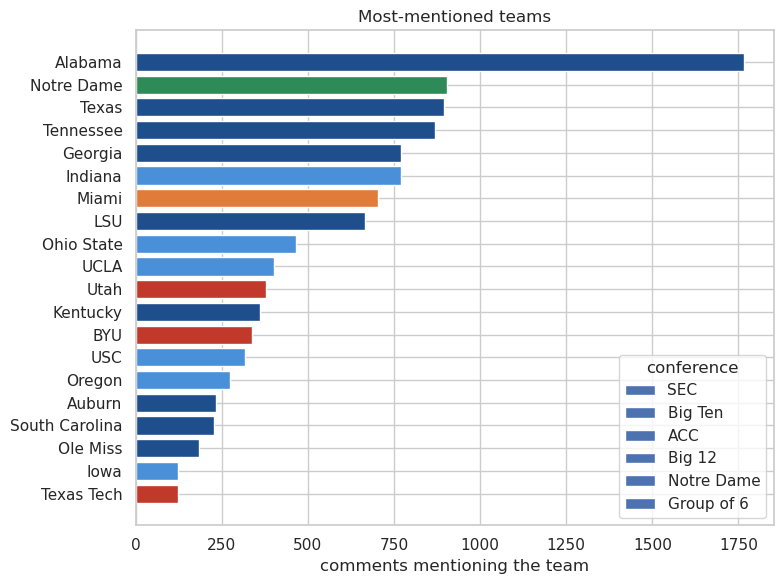

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
top = by_team.head(20).iloc[::-1]
conf_colors = {"SEC": "#1f4e8c", "Big Ten": "#4a90d9", "ACC": "#e07b39", "Big 12": "#c0392b",
               "Notre Dame": "#2e8b57", "Group of 6": "#7f7f7f"}
ax.barh(top["team"], top["mentions"], color=top["conference"].map(conf_colors))
ax.set(xlabel="comments mentioning the team", title="Most-mentioned teams")
for conf, c in conf_colors.items():
    ax.barh([], [], color=c, label=conf)
ax.legend(title="conference", loc="lower right")
save(fig, "06_top_teams.png")

In [9]:
# Direct mentions of conferences, which matter in the expansion debate (auto bids, SEC/Big Ten share)
CONF_TERMS = {"SEC": r"\bsec\b|\besecn\b", "Big Ten": r"\bbig ten\b|\bbig 10\b|\bb1g\b|\bb10\b",
              "ACC": r"\bacc\b", "Big 12": r"\bbig 12\b|\bbig twelve\b|\bxii\b", "Group of 6": r"\bg5\b|\bg6\b|group of (?:5|6|five|six)"}
conf_named = pd.DataFrame({c: df["text_body"].str.contains(p, case=False, regex=True) for c, p in CONF_TERMS.items()})
conf_named_summary = pd.DataFrame({
    "comments": conf_named.sum(),
    "mean_score": [df.loc[conf_named[c], SCORE].mean() for c in conf_named],
    "share_expansion": [df.loc[conf_named[c], "is_expansion"].mean() for c in conf_named]}).round(3)
conf_named_summary

,comments,mean_score,share_expansion
SEC,1035,0.145,0.075
Big Ten,286,0.247,0.105
ACC,117,0.361,0.197
Big 12,140,0.223,0.093
Group of 6,76,0.410,0.197


## Sentiment by conference and state

In [10]:
by_conf = (mentions.groupby("conference")
           .agg(mentions=("comment_id", "size"), teams=("team", "nunique"),
                mean_score=(SCORE, "mean"), mean_vader_std=("vader_compound", "mean"),
                neg_share=(LABEL, neg_share), expansion_share=("is_expansion", "mean"))
           .sort_values("mentions", ascending=False))
by_conf.round(3)

,mentions,teams,mean_score,mean_vader_std,neg_share,expansion_share
conference,,,,,,
SEC,6600,16,0.153,0.170,0.353,0.020
Big Ten,2730,18,0.148,0.167,0.358,0.034
Big 12,1122,16,0.181,0.193,0.332,0.044
ACC,1099,16,0.171,0.193,0.336,0.033
Notre Dame,905,1,0.171,0.194,0.334,0.039
Group of 6,117,12,0.170,0.180,0.368,0.077


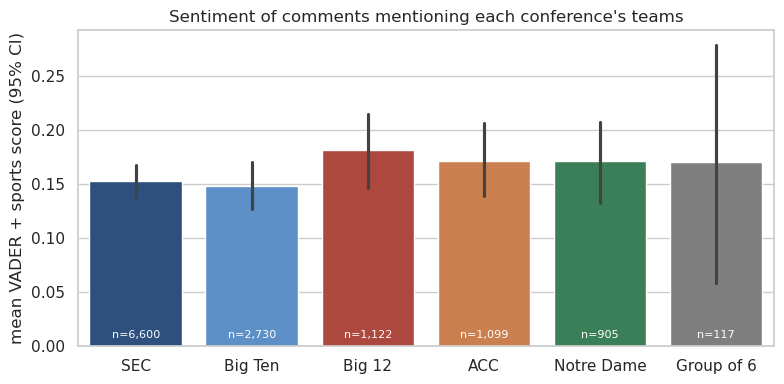

In [11]:
conf_order = by_conf.index.tolist()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=mentions, x="conference", y=SCORE, order=conf_order,
            palette=conf_colors, hue="conference", legend=False, errorbar=("ci", 95), ax=ax)
for i, conf in enumerate(conf_order):
    ax.text(i, 0.005, f"n={by_conf.loc[conf, 'mentions']:,}", ha="center", va="bottom", fontsize=8, color="white")
ax.set(xlabel=None, ylabel=f"mean {SCORE_NAME} score (95% CI)", title="Sentiment of comments mentioning each conference's teams")
save(fig, "06_conference_sentiment.png")

In [12]:
# Does the conference gap hold within each creator?
by_conf_creator = mentions.pivot_table(index="conference", columns="creator_name", values=SCORE,
                                       aggfunc=["size", "mean"]).reindex(conf_order)
by_conf_creator.round(3)

size                   mean          
creator_name Crain & Cone Josh Pate Crain & Cone Josh Pate
conference                                                
SEC                  1383      5217        0.101     0.166
Big Ten               540      2190        0.130     0.152
Big 12                221       901        0.060     0.211
ACC                   148       951        0.056     0.189
Notre Dame            112       793        0.162     0.172
Group of 6             22        95        0.211     0.161

In [13]:
# One-way ANOVA and Kruskal-Wallis across the conferences
groups = [g[SCORE].values for _, g in mentions.groupby("conference")]
f, p_f = stats.f_oneway(*groups)
h, p_h = stats.kruskal(*groups)
print(f"ANOVA F = {f:.2f}, p = {p_f:.4f};  Kruskal-Wallis H = {h:.2f}, p = {p_h:.4f}")
print("Note: one comment can appear under two conferences, so the groups are not fully independent.")

ANOVA F = 0.82, p = 0.5370;  Kruskal-Wallis H = 3.92, p = 0.5614
Note: one comment can appear under two conferences, so the groups are not fully independent.


### Before vs after the announcement, by conference (pre-announcement videos)

In [14]:
pre_m = mentions[mentions["video_published_utc"] < config.ANNOUNCE_UTC]
conf_split = pd.DataFrame({
    conf: compare(g.loc[~g["after_announce"], SCORE], g.loc[g["after_announce"], SCORE])
    for conf, g in pre_m.groupby("conference")}).T.reindex(conf_order)
conf_split.columns = ["n_before", "n_after", "mean_before", "mean_after", "diff", "cohens_d", "p_welch", "p_mannwhitney"]
conf_split.round(3)

,n_before,n_after,mean_before,mean_after,diff,cohens_d,p_welch,p_mannwhitney
SEC,3103.0,787.0,0.136,0.197,0.061,0.102,0.008,0.014
Big Ten,1524.0,270.0,0.155,0.118,-0.037,-0.064,0.348,0.359
Big 12,571.0,123.0,0.207,0.131,-0.076,-0.133,0.214,0.240
ACC,630.0,179.0,0.166,0.234,0.067,0.119,0.141,0.229
Notre Dame,589.0,118.0,0.162,0.251,0.090,0.158,0.113,0.111
Group of 6,55.0,18.0,0.157,0.082,-0.075,-0.120,0.652,0.687


### State tile map

Each state is one square. States are colored by how far their teams' mean sentiment score (VADER + sports words) is from the overall mean of all team mentions; states with fewer than 30 mentions are grey. The number is the mention count.

In [15]:
TILES = {
    "AK": (0, 0), "ME": (11, 0), "VT": (10, 1), "NH": (11, 1),
    "WA": (1, 2), "ID": (2, 2), "MT": (3, 2), "ND": (4, 2), "MN": (5, 2), "IL": (6, 2), "WI": (7, 2),
    "MI": (8, 2), "NY": (9, 2), "RI": (10, 2), "MA": (11, 2),
    "OR": (1, 3), "NV": (2, 3), "WY": (3, 3), "SD": (4, 3), "IA": (5, 3), "IN": (6, 3), "OH": (7, 3),
    "PA": (8, 3), "NJ": (9, 3), "CT": (10, 3),
    "CA": (1, 4), "UT": (2, 4), "CO": (3, 4), "NE": (4, 4), "MO": (5, 4), "KY": (6, 4), "WV": (7, 4),
    "VA": (8, 4), "MD": (9, 4), "DE": (10, 4),
    "AZ": (2, 5), "NM": (3, 5), "KS": (4, 5), "AR": (5, 5), "TN": (6, 5), "NC": (7, 5), "SC": (8, 5), "DC": (9, 5),
    "OK": (4, 6), "LA": (5, 6), "MS": (6, 6), "AL": (7, 6), "GA": (8, 6),
    "HI": (0, 7), "TX": (4, 7), "FL": (9, 7)}
MIN_STATE = 30

by_state = mentions.groupby("state").agg(mentions=("comment_id", "size"), mean_score=(SCORE, "mean"))
overall = mentions[SCORE].mean()
by_state["vs_overall"] = by_state["mean_score"] - overall
by_state.sort_values("mentions", ascending=False).round(3).head(15)

,mentions,mean_score,vs_overall
state,,,
AL,1999,0.130,-0.028
IN,1698,0.161,0.004
TX,1281,0.161,0.003
FL,933,0.164,0.007
TN,916,0.160,0.002
GA,777,0.198,0.040
CA,734,0.181,0.023
UT,715,0.191,0.033
LA,672,0.161,0.003


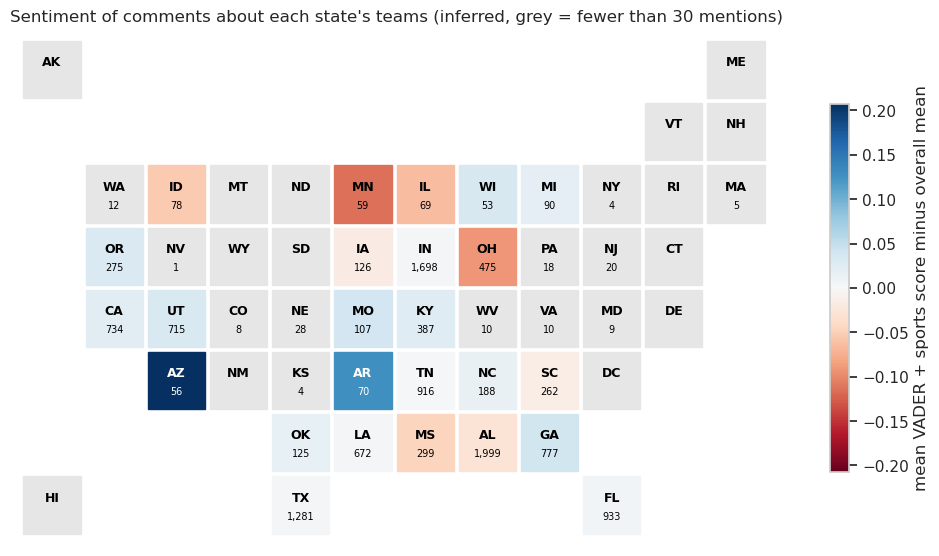

In [16]:
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle

shown = by_state[by_state["mentions"] >= MIN_STATE]
lim = shown["vs_overall"].abs().max()
norm = mcolors.TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
cmap = plt.get_cmap("RdBu")

fig, ax = plt.subplots(figsize=(10, 6.5))
for st, (col, row) in TILES.items():
    ink = "black"
    if st in shown.index:
        v = norm(shown.loc[st, "vs_overall"])
        color, n = cmap(v), f"{int(shown.loc[st, 'mentions']):,}"
        ink = "white" if abs(v - 0.5) > 0.3 else "black"
    else:
        color, n = "#e6e6e6", (f"{int(by_state.loc[st, 'mentions'])}" if st in by_state.index else "")
    ax.add_patch(Rectangle((col, -row), 0.92, 0.92, color=color))
    ax.text(col + 0.46, -row + 0.58, st, ha="center", va="center", fontsize=9, weight="bold", color=ink)
    ax.text(col + 0.46, -row + 0.28, n, ha="center", va="center", fontsize=7, color=ink)
ax.set_xlim(-0.2, 12.2); ax.set_ylim(-7.2, 1.1); ax.set_aspect("equal"); ax.axis("off")
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, shrink=0.6, label=f"mean {SCORE_NAME} score minus overall mean")
ax.set_title(f"Sentiment of comments about each state's teams (inferred, grey = fewer than {MIN_STATE} mentions)")
save(fig, "06_state_tile_map.png")

## Self-reported country (side note)

The `country` field is what a commenter put on their own channel, not where they are. Only a small share of commenters fill it in.

In [17]:
has_country = df["country"].notna()
print(f"Comments whose author lists a country: {has_country.sum():,} ({has_country.mean():.1%})")
print(f"Distinct commenters listing a country: {df.loc[has_country, 'author_channel_id'].nunique():,}")
country = df[has_country].groupby("country").agg(comments=("comment_id", "size"), mean_score=(SCORE, "mean"))
country.sort_values("comments", ascending=False).round(3)

Comments whose author lists a country: 483 (5.1%)
Distinct commenters listing a country: 268


,comments,mean_score
country,,
US,475,0.098
IT,2,0.095
DE,1,0.318
AQ,1,-0.318
IE,1,0.000
JP,1,-0.296
VI,1,0.000
VN,1,-0.008


In [18]:
print(f"US vs not listed, {SCORE_NAME}:")
compare(df.loc[~has_country, SCORE], df.loc[df["country"] == "US", SCORE]).round(3)

US vs not listed, VADER + sports:


n_a              8973.000
n_b               475.000
mean_a              0.136
mean_b              0.098
diff               -0.037
cohens_d           -0.072
p_welch             0.140
p_mannwhitney       0.165
dtype: float64

In [19]:
df[["comment_id", "teams"]].assign(teams=df["teams"].str.join("|")).to_csv(
    config.DATA_DIR / "comment_teams.csv", index=False)
by_team.to_csv(config.DATA_DIR / "team_sentiment.csv", index=False)
print("saved data/comment_teams.csv and data/team_sentiment.csv")

saved data/comment_teams.csv and data/team_sentiment.csv
